<a href="https://colab.research.google.com/github/byAnree/AF1-IAM/blob/main/AF1_IAM_STROKE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AF 1: Introducción al Aprendizaje Máquina
2077734 - Renato López Trujillo

2121978 - Edgar Andree Noyola Rangel

2226630 - Arely Carrillo Sustaita

## Análisis Exploratorio y Preprocesamiento de Datos (EDA)
**Dataset:** Stroke Prediction Dataset (Kaggle)

# **1. Carga e inspección inicial**

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [23]:
df = pd.read_csv('healthcare-dataset-stroke-data.csv')

In [24]:
# Primeras y últimas 5 filas
display(df.head())
display(df.tail())

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0
5109,44679,Female,44.0,0,0,Yes,Govt_job,Urban,85.28,26.2,Unknown,0


In [25]:
# Estructura: registros, columnas y tipos de datos
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [26]:
# Resumen estadístico de las variables numéricas
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [27]:
# Valores nulos por columna
df.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201


**Observaciones de la inspección inicial**

- El dataset tiene **5110 registros y 12 columnas**: 3 `float64`, 4 `int64` y 5 `object` (`gender`, `ever_married`, `work_type`, `Residence_type`, `smoking_status`).
- La única columna con valores nulos es `bmi`, con **201 faltantes** (4909 de 5110 valores).
- En `describe()` destaca que `age` tiene un mínimo de 0.08 (hay bebés en el dataset), que `bmi` llega a 97.6 (valor muy alto) y que `avg_glucose_level` llega a 271.74 con una media de ~106, por lo que se esperan outliers.
- La media de `stroke` es ~0.049, es decir, solo alrededor del 5% de los pacientes sufrió un derrame (clases desbalanceadas).

# **2. Limpieza, transformación y tratamiento**

## 2.1 Tratamiento de nulos en `bmi`

In [28]:
# Imputación con la mediana
mediana_bmi = df["bmi"].median()
df["bmi"] = df["bmi"].fillna(mediana_bmi)
print("Mediana de bmi usada para imputar:", mediana_bmi)

Mediana de bmi usada para imputar: 28.1


In [29]:
# Verificación: ya no deben quedar nulos
df.isnull().sum()

,0
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,0


Se imputaron los 201 nulos de `bmi` con la **mediana (28.1)**. Se eligió la mediana y no la media porque es menos sensible a valores extremos (como el máximo de 97.6).

## 2.2 Detección de valores atípicos (método IQR) en `avg_glucose_level`

In [30]:
glucosa = df["avg_glucose_level"]

q1 = np.percentile(glucosa, 25)
q3 = np.percentile(glucosa, 75)
IQR = q3 - q1

lim_inferior = q1 - 1.5 * IQR
lim_superior = q3 + 1.5 * IQR

print('Q1 =', q1)
print('Q3 =', q3)
print('IQR =', IQR)
print('Límite inferior =', round(lim_inferior, 2))
print('Límite superior =', round(lim_superior, 2))

Q1 = 77.245
Q3 = 114.09
IQR = 36.845
Límite inferior = 21.98
Límite superior = 169.36


In [31]:
es_outlier = (glucosa < lim_inferior) | (glucosa > lim_superior)

print("Número de outliers:", es_outlier.sum())
print("Porcentaje de outliers:", round(es_outlier.mean() * 100, 2), "%")
print("Outliers por debajo del límite inferior:", (glucosa < lim_inferior).sum())
print("Outliers por encima del límite superior:", (glucosa > lim_superior).sum())

df[es_outlier].head()

Número de outliers: 627
Porcentaje de outliers: 12.27 %
Outliers por debajo del límite inferior: 0
Outliers por encima del límite superior: 627


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.1,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
5,56669,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1


**Observaciones sobre los outliers**

- Se identificaron **627 valores atípicos (12.27%)** en `avg_glucose_level`, todos **por encima del límite superior (169.36)**; ninguno por debajo del límite inferior (21.98), ya que el mínimo de la columna es 55.12.
- Se decidió **no eliminarlos**: una glucosa alta es clínicamente posible (por ejemplo, en pacientes con diabetes) y puede ser justamente información relevante para predecir el riesgo de derrame. La actividad solo pide identificarlos.

## 2.3 Codificación de variables categóricas

In [32]:
print(df["gender"].value_counts())
print(df["ever_married"].value_counts())
print(df["work_type"].value_counts())
print(df["Residence_type"].value_counts())
print(df["smoking_status"].value_counts())

gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64
ever_married
Yes    3353
No     1757
Name: count, dtype: int64
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22
Name: count, dtype: int64
Residence_type
Urban    2596
Rural    2514
Name: count, dtype: int64
smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789
Name: count, dtype: int64


**Decisión de codificación**

- `ever_married` y `Residence_type` son **binarias**, por lo que se codifican con `map()`: Yes = 1 / No = 0 y Urban = 1 / Rural = 0.
- `gender`, `work_type` y `smoking_status` tienen varias categorías **sin orden natural**, por lo que se usa **One-Hot Encoding** con `pd.get_dummies()` (con un orden numérico el modelo asumiría una jerarquía que no existe). Se conservan todas las categorías (sin `drop_first`).
- Nota: `gender` tiene una categoría `Other` con un único registro, y `smoking_status` tiene 1544 casos `Unknown` (~30%); se dejan como categorías propias.

In [33]:
# Copia de respaldo antes de codificar (ya con bmi imputado)
df_original = df.copy()

In [34]:
# Esta celda se puede ejecutar varias veces: siempre parte de la copia
df = df_original.copy()

# Binarias con map()
df["ever_married"] = df["ever_married"].map({"Yes": 1, "No": 0})
df["Residence_type"] = df["Residence_type"].map({"Urban": 1, "Rural": 0})

# Multicategoría con One-Hot Encoding (dtype=int para obtener 0/1)
df = pd.get_dummies(df, columns=["gender", "work_type", "smoking_status"], dtype=int)

# 2.4 Eliminar la columna id (no aporta información predictiva)
df = df.drop(columns=["id"])

In [35]:
# Verificación: todo numérico, sin nulos y sin la columna id
df.info()
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 20 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   age                             5110 non-null   float64
 1   hypertension                    5110 non-null   int64  
 2   heart_disease                   5110 non-null   int64  
 3   ever_married                    5110 non-null   int64  
 4   Residence_type                  5110 non-null   int64  
 5   avg_glucose_level               5110 non-null   float64
 6   bmi                             5110 non-null   float64
 7   stroke                          5110 non-null   int64  
 8   gender_Female                   5110 non-null   int64  
 9   gender_Male                     5110 non-null   int64  
 10  gender_Other                    5110 non-null   int64  
 11  work_type_Govt_job              5110 non-null   int64  
 12  work_type_Never_worked          51

,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,stroke,gender_Female,gender_Male,gender_Other,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,1,1,228.69,36.6,1,0,1,0,0,0,1,0,0,0,1,0,0
1,61.0,0,0,1,0,202.21,28.1,1,1,0,0,0,0,0,1,0,0,0,1,0
2,80.0,0,1,1,0,105.92,32.5,1,0,1,0,0,0,1,0,0,0,0,1,0
3,49.0,0,0,1,1,171.23,34.4,1,1,0,0,0,0,1,0,0,0,0,0,1
4,79.0,1,0,1,0,174.12,24.0,1,1,0,0,0,0,0,1,0,0,0,1,0


**Resultado del preprocesamiento:** el DataFrame final tiene **5110 registros y 20 columnas**, todas numéricas (`int64` y `float64`), sin valores nulos y sin la columna `id`.

# **3. Análisis visual y exploratorio**

## 3.1 Distribución de la variable objetivo

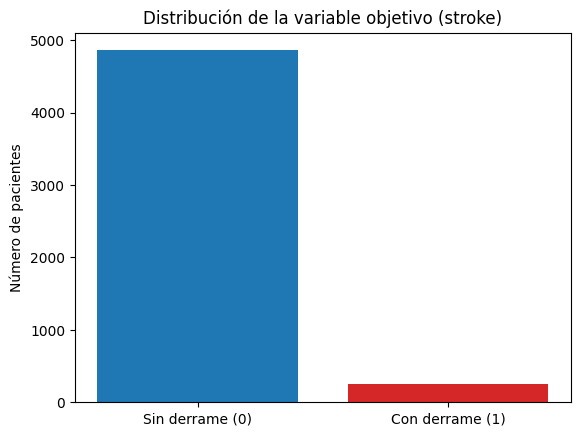

stroke
0    4861
1     249
Name: count, dtype: int64
stroke
0    95.13
1     4.87
Name: count, dtype: float64


In [36]:
conteo = df["stroke"].value_counts().sort_index()

plt.bar(["Sin derrame (0)", "Con derrame (1)"], conteo.values, color=["tab:blue", "tab:red"])
plt.title("Distribución de la variable objetivo (stroke)")
plt.ylabel("Número de pacientes")
plt.show()

print(conteo)
print((conteo / conteo.sum() * 100).round(2))

## 3.2 Histogramas de edad y glucosa por grupo

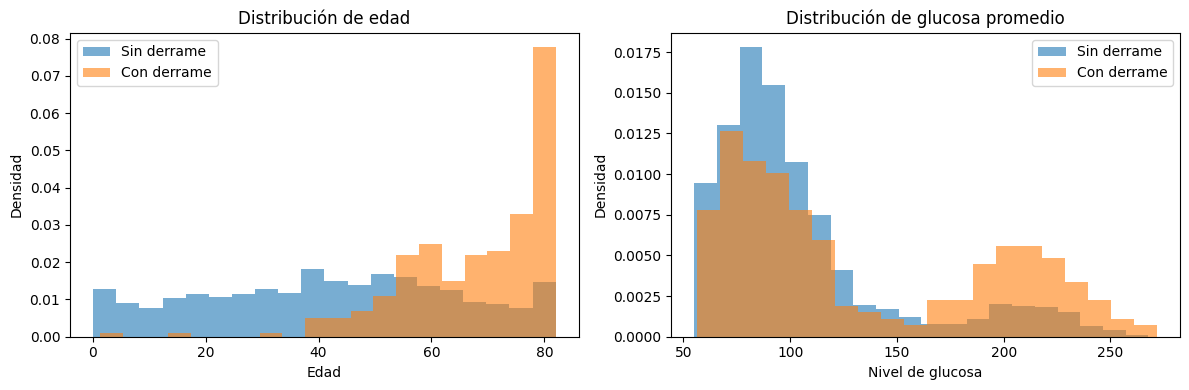

In [37]:
con = df[df["stroke"] == 1]
sin = df[df["stroke"] == 0]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(sin["age"], bins=20, alpha=0.6, density=True, label="Sin derrame")
axes[0].hist(con["age"], bins=20, alpha=0.6, density=True, label="Con derrame")
axes[0].set_title("Distribución de edad")
axes[0].set_xlabel("Edad")
axes[0].set_ylabel("Densidad")
axes[0].legend()

axes[1].hist(sin["avg_glucose_level"], bins=20, alpha=0.6, density=True, label="Sin derrame")
axes[1].hist(con["avg_glucose_level"], bins=20, alpha=0.6, density=True, label="Con derrame")
axes[1].set_title("Distribución de glucosa promedio")
axes[1].set_xlabel("Nivel de glucosa")
axes[1].set_ylabel("Densidad")
axes[1].legend()

plt.tight_layout()
plt.show()

## 3.3 Relación entre edad y nivel de glucosa

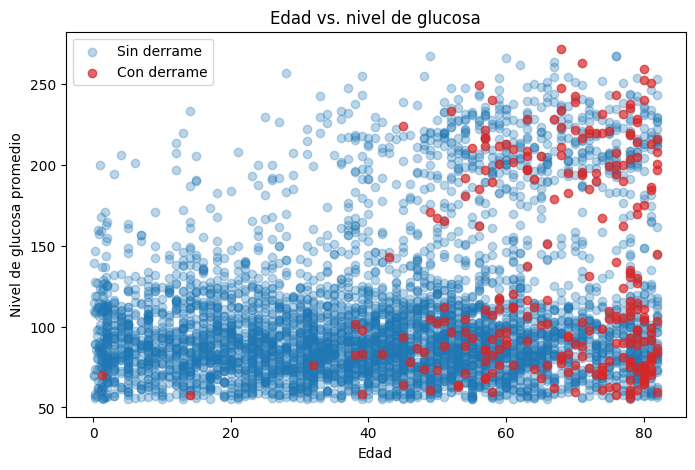

In [38]:
plt.figure(figsize=(8, 5))
plt.scatter(sin["age"], sin["avg_glucose_level"], c="tab:blue", alpha=0.3, label="Sin derrame")
plt.scatter(con["age"], con["avg_glucose_level"], c="tab:red", alpha=0.7, label="Con derrame")
plt.title("Edad vs. nivel de glucosa")
plt.xlabel("Edad")
plt.ylabel("Nivel de glucosa promedio")
plt.legend()
plt.show()

Descarga del Dataset Limpio

In [39]:
df.to_csv("stroke_limpio.csv", index=False)

In [40]:
from google.colab import files
files.download("stroke_limpio.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 3.4 Conclusión del EDA

El dataset está fuertemente desbalanceado: de 5110 pacientes, solo 249 (4.87%) sufrieron un derrame, frente a 4861 (95.13%) que no. Esto es importante porque un modelo podría obtener una exactitud alta simplemente prediciendo "sin derrame" siempre, por lo que habrá que tenerlo en cuenta al entrenar y evaluar.

De acuerdo con las gráficas, la **edad** es el factor más determinante. En el histograma, los pacientes sin derrame se distribuyen en todas las edades, mientras que los casos con derrame se concentran a partir de los 50 años y aumentan de forma marcada entre los 60 y los 80, con muy pocos casos en menores de 40. El diagrama de dispersión lo confirma: casi todos los puntos rojos aparecen en la mitad derecha de la gráfica.

El **nivel de glucosa** parece un segundo factor relevante, aunque menos claro. Ambos grupos se concentran en valores de entre 70 y 110, pero los pacientes con derrame muestran una segunda concentración en niveles altos (alrededor de 190 a 250), que casi no existe en el grupo sin derrame. En el scatter, la zona de edad avanzada con glucosa alta tiene una proporción notable de puntos rojos. Sin embargo, una parte importante de los derrames también ocurre con glucosa normal, así que la glucosa por sí sola no basta para distinguir los casos.

En resumen, el riesgo parece aumentar con la edad avanzada y, en menor medida, con niveles altos de glucosa, y la combinación de ambos factores concentra más casos. Estas observaciones son visuales y muestran asociación, no causalidad; para confirmarlas haría falta analizar también otras variables, como hipertensión y enfermedad cardíaca, y aplicar pruebas estadísticas.